*Text under CC-BY 4.0, code under BSD-3-Clause. (c) 2026 Francesco Mario Antonio Mitrotta.*

# Above the Element-Size Ceiling: What Abaqus Does, and Why an Uncertainty Study Should Care

NB6 derived a ceiling on the element size of the energy-based softening law, $L_c<2EG/\sigma_0^2$, and built its mesh around it. It left one question open: what does Abaqus do with an element that is *larger* than the ceiling? The tempting answer is that the element fails the moment damage starts, because the law would have to snap back. This notebook tests that answer on NB1's single element, whose size we can change at will, and finds that Abaqus does something else, without saying so. It then makes the material properties uncertain, as in the rest of the series, to show why this matters for a campaign.

## Learning goal

By the end of this notebook you will be able to say what Abaqus does to an element above the ceiling, and to give the energy that element dissipates as a function of its size. You will also be able to show that, with uncertain material properties, an element that respects the ceiling at the nominal values breaches it for part of the inputs, which biases those runs. Finally, you will be able to say why this bias leaves the peak load of one element untouched, and why it does not leave the peak load of a structure untouched.

## Prerequisites

[NB1](01_fiber_tension_single_element.ipynb) (crack band, $\delta_0$ and $\delta_f$, run or load), [NB2](02_monte_carlo_fiber_strength.ipynb) (Monte Carlo campaign) and [NB6](06_open_hole_tension.ipynb) (the ceiling). Nothing else is needed.

## Roadmap

1. **The ceiling and what we expect above it**: NB1's element, made larger.
2. **Growing the element**: eleven Abaqus runs from 25 to 600 mm, with stress plotted against strain and against displacement.
3. **The energy Abaqus really dissipates**, compared with the fracture energy we prescribed, and the warnings it gives (none useful).
4. **An uncertain ceiling**: Normal $E_1$, $G_{fT}$ and $X_T$ with CoV 10%, and a campaign on an element that is safe at the nominal values.

Two simplifications, both stated where they apply: every run has `nlgeom=OFF`, as in NB2's campaign, so the response before damage is linear; and only fibre tension is tested. The matrix modes use the same evolution law in Abaqus's documentation, but we did not run them.

## Part 1 &ndash; The ceiling, and what we expect above it

NB1 wrote the softening law against the equivalent displacement $\delta=L_c\,\varepsilon$, with two corners. The onset $\delta_0=L_c\,X_T/E_1$ grows with the element size $L_c$, and the full failure $\delta_f=2G_{fT}/X_T$ is fixed by the material. NB6 turned the condition $\delta_0\le\delta_f$ into a ceiling,
$$L_{c,\max}=\frac{2\,E_1\,G_{fT}}{X_T^{2}},$$
where $L_{c,\max}$ [mm] is the largest element for which the law is a proper triangle, $E_1$ [MPa] is the fibre-direction modulus, $G_{fT}$ [N/mm] the fibre-tension fracture energy and $X_T$ [MPa] the fibre tensile strength. We write $r=L_c/L_{c,\max}$ for the size of an element relative to its ceiling. Abaqus's [documentation](https://docs.software.vt.edu/abaqusv2025/English/SIMACAEMATRefMap/simamat-c-damageevolfibercomposite.htm) defines $L_c$ and the law, and says nothing about elements above the ceiling.

The cell below computes the ceiling for NB1's material and compares NB1's own 10 mm element with an element exactly at the ceiling.

In [1]:
import json                                        # read back the JSON files the Abaqus script writes
import sys                                         # to extend the module search path
from pathlib import Path                           # file paths that work on Windows and Linux

import matplotlib.pyplot as plt                    # figures
import numpy as np                                 # arrays and the trapezoidal rule

sys.path.insert(0, "../scripts")                   # the series' shared notebook-side helpers live in scripts/
from mc_campaign import run_one_sample             # NB2's run or load for one sample; extra key=value tokens go to the script

# NB1's material (Nelson, Riddle & Cairns, 2017) and shell thickness.
E1, X_T, G_FT, T = 40600.0, 990.0, 1290.0, 0.2     # E_1 [MPa], X_T [MPa], G_fT [N/mm], thickness t [mm]


def ceiling(e1, x_t, g_ft):
    """Element-size ceiling L_c,max = 2 E1 G_fT / X_T^2 [mm] of fibre tension (NB6).

    e1 : fibre-direction modulus [MPa]; x_t : fibre tensile strength [MPa]; g_ft : fracture energy [N/mm].
    Works on numbers and on NumPy arrays alike.
    """
    return 2.0 * e1 * g_ft / x_t**2                # the formula of this Part


LC_MAX = ceiling(E1, X_T, G_FT)                    # the ceiling at the nominal values [mm]
DELTA_F = 2 * G_FT / X_T                           # full-failure displacement, fixed by the material [mm]
for lc in (10.0, LC_MAX):                          # NB1's element, then an element exactly at the ceiling
    delta_0 = lc * X_T / E1                        # onset displacement of an element of size lc [mm]
    print(f"L_c = {lc:6.1f} mm   r = {lc / LC_MAX:.2f}   delta_0 = {delta_0:.3f} mm   delta_f = {DELTA_F:.3f} mm")

L_c =   10.0 mm   r = 0.09   delta_0 = 0.244 mm   delta_f = 2.606 mm
L_c =  106.9 mm   r = 1.00   delta_0 = 2.606 mm   delta_f = 2.606 mm


NB1's element is far below its ceiling: 10 mm against 106.9 mm, so $r=0.09$, and its onset displacement ($\delta_0=0.244$ mm) is a tenth of $\delta_f=2.606$ mm. An element of exactly 106.9 mm is the borderline case: $\delta_0=\delta_f$, and the softening branch is vertical (NB6's orange curve).

**What do we expect above the ceiling?** There $\delta_0>\delta_f$: the law would have to reach zero stress *before* the stress reaches the strength. That is a snap-back, which a law moving only forward in $\delta$ cannot follow. The natural guess is that the element then fails the moment damage starts. It would dissipate only the elastic energy it stored up to the onset, $\tfrac12X_T\,\delta_0=r\,G_{fT}$ per unit crack area. Part 2 tests that guess.

## Part 2 &ndash; Growing the element

To grow the element we only change the edge of NB1's square: for a single S4R element, $L_c=\sqrt A$ is the edge. `build_fiber_tension.py` gains three optional parameters for this notebook. They are `size=` (the edge), `E1=` and `maxinc=` (a cap on the increment, so that the softening branch is recorded in many frames). It also saves the distinct warnings Abaqus wrote to its message file. Without these parameters it behaves exactly as in NB1 to NB3.

We keep NB1's material and run eleven edges from 25 to 600 mm: four below the ceiling and seven above it, with $r$ from 0.23 to 5.6. Each run follows NB1's *run or load* pattern through NB2's `run_one_sample`: Abaqus starts only if the run's JSON file in `runs/nb07/` is missing. One element solve takes about a minute and one set of solver licences. Each run ends at $U_1=1.5\,(\delta_0+\delta_f)$, so that it stops after the element has failed, whichever softening branch Abaqus follows.

In [2]:
RUNS = Path("../runs/nb07")      # this notebook's own results folder
MAXINC = 0.005                   # largest increment, as a fraction of the step: at most 200 increments per run
EDGES = [25, 50, 75, 100, 110, 125, 150, 200, 300, 450, 600]    # element edges L_c [mm]; the ceiling is 106.9 mm


def run_edge(lc, e1, x_t, g_ft):
    """Run (or load) NB1's element of edge `lc` [mm] in fibre tension, and return its saved results.

    The run ends at U1 = 1.5 (delta_0 + delta_f) [mm]. Run or load: Abaqus starts only if the
    JSON file of this edge is missing.
    """
    u1_end = 1.5 * (lc * x_t / e1 + 2 * g_ft / x_t)      # 1.5 (delta_0 + delta_f) for this element [mm]
    data, _ = run_one_sample(x_t, RUNS / f"size_{lc:03d}.json", u1_end, nlgeom="OFF",
                             G_fT=g_ft, E1=e1, size=lc, maxinc=MAXINC)    # extra key=value tokens for the script
    return data                                          # u1, rf1, damage_ft, msg_warnings, ... of the run


runs = {lc: run_edge(lc, E1, X_T, G_FT) for lc in EDGES}      # edge -> saved results of its run
frames = [len(res["u1"]) for res in runs.values()]            # recorded frames of every run
print(f"{len(runs)} runs ready, with {min(frames)} to {max(frames)} recorded frames each.")

11 runs ready, with 201 to 201 recorded frames each.


Every run recorded 201 frames, the starting state plus 200 increments of 0.005 of the step. That is enough to follow the softening branch of every element, including the longest and the shortest.

The cell below plots six of the eleven runs (the other five join them in Part 3). Each run is drawn twice: as nominal stress against **strain** $\varepsilon=u/L_c$, and against **displacement** $u$, which for one element is the equivalent displacement $\delta$. The nominal stress is the reaction force over the cross-section, $P/(L_c\,t)$.

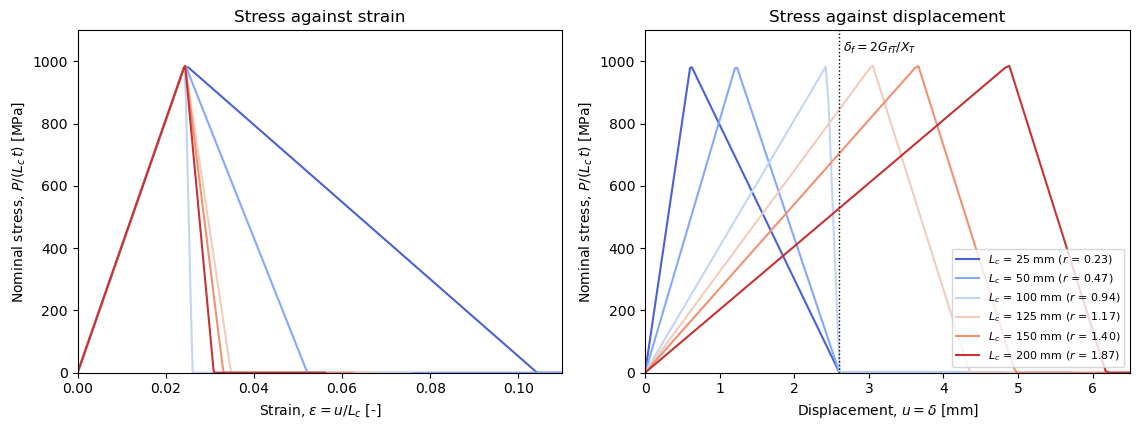

In [3]:
SHOWN = [25, 50, 100, 125, 150, 200]                             # six of the eleven edges, to keep the figure readable
colours = plt.cm.coolwarm(np.linspace(0.05, 0.95, len(SHOWN)))   # blue = below the ceiling (r < 1), red = above it

fig, (ax_eps, ax_delta) = plt.subplots(1, 2, figsize=(11.5, 4.4))     # left: against strain; right: against displacement
for lc, colour in zip(SHOWN, colours):
    u = np.array(runs[lc]["u1"])                                 # edge displacement = equivalent displacement delta [mm]
    stress = np.array(runs[lc]["rf1"]) / (lc * T)                # nominal stress: force over width x thickness [MPa]
    label = f"$L_c$ = {lc} mm ($r$ = {lc / LC_MAX:.2f})"         # legend entry, with the size relative to the ceiling
    ax_eps.plot(u / lc, stress, color=colour, label=label)       # strain = displacement / L_c
    ax_delta.plot(u, stress, color=colour, label=label)          # the same curve against displacement
ax_delta.axvline(DELTA_F, color="k", ls=":", lw=1)               # the full-failure displacement the material prescribes
ax_delta.text(DELTA_F + 0.05, 1030, r"$\delta_f=2G_{fT}/X_T$", fontsize=9)    # label of that line
ax_eps.set(xlabel=r"Strain, $\varepsilon=u/L_c$ [-]", ylabel=r"Nominal stress, $P/(L_c\,t)$ [MPa]",
           xlim=(0, 0.11), ylim=(0, 1100), title="Stress against strain")      # axes of the left panel
ax_delta.set(xlabel=r"Displacement, $u=\delta$ [mm]", ylabel=r"Nominal stress, $P/(L_c\,t)$ [MPa]",
             xlim=(0, 6.5), ylim=(0, 1100), title="Stress against displacement")    # axes of the right panel
ax_delta.legend(fontsize=8, loc="lower right")                   # one legend serves both panels
fig.tight_layout()                                               # avoid overlapping labels
plt.show()

**Left, stress against strain.** All six elements share the same elastic line and peak at the same strain, $\varepsilon_0=X_T/E_1=0.024$: the onset strain is a material property. After the peak, the failure strain depends on the size, as the crack band requires. It is $\delta_f/L_c=0.104$ for the 25 mm element and 0.052 for the 50 mm one, and for the 100 mm element ($r=0.94$) it has shrunk to about 0.026, barely above $\varepsilon_0$.

The three elements above the ceiling should fail at $\delta_f/L_c=0.021$, 0.017 and 0.013, all *below* $\varepsilon_0$: failing before the onset. They do not. They fail at about 0.035, 0.033 and 0.031, after a softening branch. Note also that all six peak at the same stress, $X_T=990$ MPa, those above the ceiling included: Part 3 comes back to this.

**Right, stress against displacement.** The three elements below the ceiling return to zero stress at the same displacement, the dotted $\delta_f=2.606$ mm, while their peaks move to the right with the size. This is the crack band at work: $\delta_f$ is fixed by the material and $\delta_0$ by the element.

At that displacement the three elements above the ceiling have not even reached their peak. They return to zero stress only at 4.4, 5.0 and 6.2 mm. The guess of Part 1 is wrong too, since no element drops vertically at its onset: each softens over a finite branch. So above the ceiling the failure displacement is no longer set by the material; it grows with the element.

## Part 3 &ndash; The energy Abaqus really dissipates

The cleanest way to compare elements of different sizes is the energy they absorb per unit crack area. The work done on the element is $\int P\,\mathrm du$, the area under its force&ndash;displacement curve. The crack it opens has area $L_c\,t$. Once the element has failed completely it stores none of that work, so
$$G_{\mathrm{eff}}=\frac{1}{L_c\,t}\int_0^{u_{\mathrm{end}}}P\,\mathrm du,$$
where $G_{\mathrm{eff}}$ [N/mm] is the fracture energy the element actually dissipated, $P$ [N] the reaction force, $u$ [mm] the edge displacement, $t$ [mm] the thickness and $u_{\mathrm{end}}$ the last displacement of the run. If Abaqus honoured the law we prescribed, $G_{\mathrm{eff}}=G_{fT}$ for every element, and the softening branch would be $\delta_f-\delta_0$ long.

The cell below integrates each run with the trapezoidal rule. It prints $G_{\mathrm{eff}}/G_{fT}$ and the length of the softening branch, that is the displacement between the onset $\delta_0$ and the force reaching zero. It then plots $G_{\mathrm{eff}}/G_{fT}$ against $r$ for the eleven runs, with three lines: the prescribed $G_{fT}$, the guess of Part 1 (the element fails at the onset, $r\,G_{fT}$) and the line $(r+\tfrac12)\,G_{fT}$, which we will read off the table.

G_fT/X_T = 1.303 mm (half of delta_f); below the ceiling the branch should be delta_f - delta_0
 L_c [mm]      r  branch past onset [mm]  G_eff/G_fT
       25   0.23                   2.019        1.00
       50   0.47                   1.392        1.00
       75   0.70                   0.799        1.00
      100   0.94                   0.172        1.00
      110   1.03                   1.324        1.53
      125   1.17                   1.320        1.67
      150   1.40                   1.322        1.90
      200   1.87                   1.353        2.37
      300   2.81                   1.316        3.31
      450   4.21                   1.350        4.71
      600   5.61                   1.399        6.11


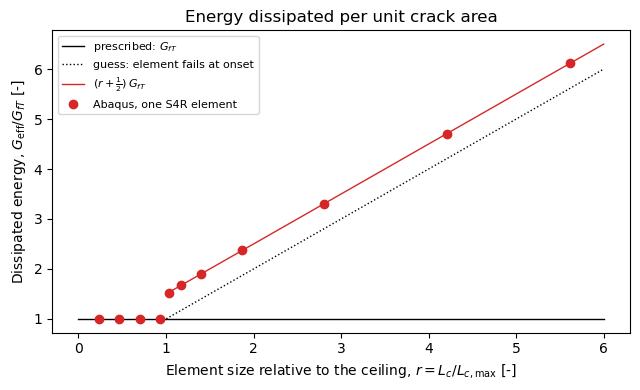

In [4]:
def dissipated_energy(u, p, lc, t):
    """Energy per unit crack area G_eff [N/mm] absorbed by an element that has failed completely.

    u : edge displacement per frame [mm]; p : reaction force per frame [N];
    lc : element edge L_c [mm]; t : shell thickness [mm].
    """
    assert abs(p[-1]) < 1e-6 * p.max(), "the run must end after the element has failed"    # no energy left in the element
    return np.trapezoid(p, u) / (lc * t)       # area under P(u), over the crack area lc * t


def failure_displacement(u, p):
    """Displacement [mm] of the first frame after the peak where the force is zero (to within one increment)."""
    k = int(np.argmax(p))                                   # frame of the peak force
    return u[k + int(np.argmax(p[k:] < 1e-6 * p.max()))]    # first frame at or after the peak with (numerically) zero force


print(f"G_fT/X_T = {G_FT / X_T:.3f} mm (half of delta_f); below the ceiling the branch should be delta_f - delta_0")
print(f"{'L_c [mm]':>9} {'r':>6} {'branch past onset [mm]':>23} {'G_eff/G_fT':>11}")                # table header
r_all, g_eff = [], []                                        # r and G_eff / G_fT of every run, for the figure
for lc, res in runs.items():
    u, p = np.array(res["u1"]), np.array(res["rf1"])         # displacement [mm] and force [N] of this run
    r = lc / LC_MAX                                          # size relative to the ceiling
    ratio = dissipated_energy(u, p, lc, T) / G_FT            # energy actually dissipated, relative to the prescribed G_fT
    branch = failure_displacement(u, p) - lc * X_T / E1      # length of the softening branch: zero force minus onset [mm]
    print(f"{lc:9d} {r:6.2f} {branch:23.3f} {ratio:11.2f}")  # one row per run
    r_all.append(r)                                          # keep for the figure
    g_eff.append(ratio)

fig, ax = plt.subplots(figsize=(6.5, 4))                     # one panel
r_line = np.linspace(0, 6, 300)                              # r values for the reference lines
ax.plot(r_line, np.ones_like(r_line), "k-", lw=1, label=r"prescribed: $G_{fT}$")                              # what we asked for
ax.plot(r_line[r_line > 1], r_line[r_line > 1], "k:", lw=1, label=r"guess: element fails at onset")           # instant failure at the onset
ax.plot(r_line[r_line > 1], r_line[r_line > 1] + 0.5, color="C3", lw=1, label=r"$(r+\frac{1}{2})\,G_{fT}$")   # the rule suggested by the table
ax.plot(r_all, g_eff, "o", color="C3", label="Abaqus, one S4R element")                                       # the eleven runs
ax.set(xlabel=r"Element size relative to the ceiling, $r=L_c/L_{c,\max}$ [-]",
       ylabel=r"Dissipated energy, $G_{\mathrm{eff}}/G_{fT}$ [-]", title="Energy dissipated per unit crack area")
ax.legend(fontsize=8)
fig.tight_layout()                                           # avoid overlapping labels
plt.show()

**Below the ceiling** ($r\le0.94$), $G_{\mathrm{eff}}/G_{fT}=1.00$ for all four elements: Abaqus honours the law we asked for, whatever the size. The softening branch is the prescribed $\delta_f-\delta_0$ and shrinks as the element grows, from 2.02 mm for the 25 mm element to 0.17 mm for the 100 mm one.

**Above the ceiling** the branch stops shrinking. It is 1.32 to 1.40 mm long for all seven elements, whatever the size: $G_{fT}/X_T=1.303$ mm, a length fixed by the material alone, to within one increment (up to 0.13 mm for the longest runs). The area under that triangle is the elastic energy up to the onset, $\frac{1}{2}X_T\delta_0=r\,G_{fT}$, plus $\frac{1}{2}X_T\,(G_{fT}/X_T)=\frac{1}{2}G_{fT}$ from the branch, so $G_{\mathrm{eff}}=(r+\frac{1}{2})\,G_{fT}$: the seven runs (1.53 to 6.11) sit on the red line, half a fracture energy above the guess of Part 1. The dissipated energy therefore *jumps* from $1.00\,G_{fT}$ to $1.53\,G_{fT}$ between the 100 mm and the 110 mm element, 3% above the ceiling, and the 600 mm element dissipates six times what we prescribed. The rule is an empirical fit to eleven runs, of one failure mode in one Abaqus version (2023); Abaqus's documentation does not state it. It reproduces the numbers, though: above the ceiling, Abaqus behaves as if the material's fracture energy were larger than the one we gave it.

> **Note:** The extra energy does not change the **peak load** of this single element. The peak is reached at the damage onset, $\sigma=X_T$, before the softening branch starts, and nothing else carries load, so the peak force is $X_T\,L_c\,t$ whatever branch Abaqus follows afterwards (Part 2's figure: all peaks at 990 MPa). The bias is therefore invisible in the peak of one element. In a structure it is not, as Part 4 explains.

**Does Abaqus warn us?** Abaqus writes its warnings to a message file. The script saved the distinct ones of every run, so the cell below lists them with the edges of the runs that wrote each one.

In [5]:
# The warnings Abaqus wrote (distinct texts), and the runs whose message file contained each one.
warnings = {}                                                # warning text -> list of edges whose message file has it
for lc, res in runs.items():
    for w in res["msg_warnings"]:                            # the distinct warnings saved with this run
        warnings.setdefault(w, []).append(lc)                # remember which runs wrote it
print("Warnings in the message files:")                      # heading of the list
for w, edges in warnings.items():                           # one entry per distinct warning
    print(f"  {w}\n      L_c = {edges} mm")                  # the text, then the runs that wrote it

Warnings in the message files:
  SOLVER PROBLEM. NUMERICAL SINGULARITY WHEN PROCESSING NODE PLY-1.2
      L_c = [25, 50, 75, 100, 110, 125, 150, 200, 300, 450, 600] mm
  SOLVER PROBLEM. NUMERICAL SINGULARITY WHEN PROCESSING NODE PLY-1.3
      L_c = [25, 50, 75, 100, 110, 125, 150, 200, 300, 450, 600] mm
  THE SYSTEM MATRIX HAS 1 NEGATIVE EIGENVALUES.
      L_c = [25, 50, 75, 100, 110, 125, 150, 200, 300, 450, 600] mm


The three warnings are the same texts in all eleven runs, below and above the ceiling. One is a negative eigenvalue (a softening element has a negative tangent stiffness). The other two are numerical singularities at the element's nodes, which we read as the fully damaged element having no stiffness left. None mentions the fracture energy, the element size or the ceiling. Nothing in the output tells you that a run is above the ceiling.

## Part 4 &ndash; When the ceiling is uncertain

An uncertainty study makes the material properties random, and the ceiling $2E_1G_{fT}/X_T^2$ is built from three of them. [Thapa et al. (2021)](https://doi.org/10.1007/s00158-020-02690-5) take every ply property Normal with a coefficient of variation of 10%. We adopt that for $E_1$, $G_{fT}$ and $X_T$, with $x=\mu\,(1+0.1\,z)$ and $z$ a standard Normal draw. The input seeds are the series' ($X_T$: 2, $G_{fT}$: 6) and a new one for $E_1$ (10).

A first-order estimate says the ceiling's CoV is about $\sqrt{0.1^2+0.1^2+4\times0.1^2}\approx25\%$: $E_1$ and $G_{fT}$ enter once, but $X_T$ enters squared. The cell below draws 100,000 samples of the ceiling (a formula, no Abaqus) and asks two questions of an element of edge 85 mm. That element has $r=0.80$ at the nominal values, a margin of 20% that one would call safe. How often does a sampled ceiling fall below it? And how small must an element be to stay below the ceiling in 95% of the samples?

nominal ceiling 106.9 mm; sampled ceiling: mean 110.3 mm, std 28.3 mm, CoV 26%, 5th to 95th percentile 71.7 to 162.1 mm
an element of 85 mm (r = 0.80 at the nominal values) is above the ceiling in 17.7% of the samples


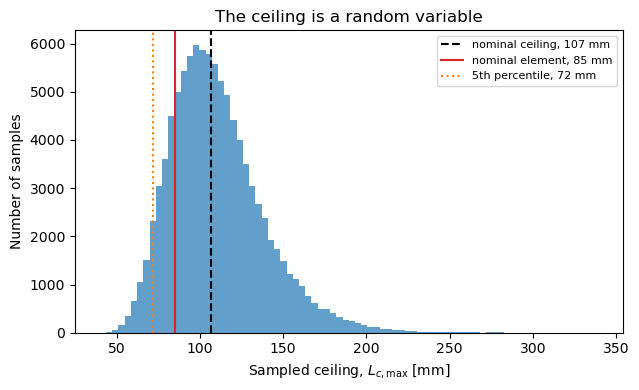

In [6]:
COV = 0.10                                        # Thapa et al.: every input Normal with a CoV of 10%
N_MC = 100_000                                    # samples of the ceiling (a formula, no Abaqus)
SEEDS = {"X_T": 2, "G_fT": 6, "E1": 10}           # the series' X_T and G_fT seeds, and a new one for E1
LC_ELEMENT = 85.0                                 # edge of the element we consider safe: r = 0.80 at the nominal values [mm]


def draw(mean, seed, n):
    """n Normal samples x = mean (1 + COV z), with z standard Normal from a generator seeded with `seed`."""
    return mean * (1 + COV * np.random.default_rng(seed).standard_normal(n))     # x = mu (1 + CoV z)


x_t_s = draw(X_T, SEEDS["X_T"], N_MC)             # sampled fibre tensile strengths [MPa]
g_ft_s = draw(G_FT, SEEDS["G_fT"], N_MC)          # sampled fibre-tension fracture energies [N/mm]
e1_s = draw(E1, SEEDS["E1"], N_MC)                # sampled fibre-direction moduli [MPa]
lc_max_s = ceiling(e1_s, x_t_s, g_ft_s)           # one ceiling per sample [mm]

p_breach = np.mean(lc_max_s < LC_ELEMENT)         # share of samples whose ceiling is below the element
q05 = np.percentile(lc_max_s, 5)                  # element size that stays below the ceiling in 95% of the samples
# Summary of the sampled ceiling: its centre, spread (CoV) and the 5th to 95th percentile range.
print(f"nominal ceiling {LC_MAX:.1f} mm; sampled ceiling: mean {lc_max_s.mean():.1f} mm, std {lc_max_s.std():.1f} mm, "
      f"CoV {lc_max_s.std() / lc_max_s.mean():.0%}, 5th to 95th percentile {q05:.1f} to {np.percentile(lc_max_s, 95):.1f} mm")
# How often the element we consider safe turns out to be above the ceiling.
print(f"an element of {LC_ELEMENT:.0f} mm (r = {LC_ELEMENT / LC_MAX:.2f} at the nominal values) is above the ceiling in {p_breach:.1%} of the samples")

fig, ax = plt.subplots(figsize=(6.5, 4))                                           # one panel
ax.hist(lc_max_s, bins=80, color="C0", alpha=0.7)                                  # the distribution of the sampled ceiling
ax.axvline(LC_MAX, color="k", ls="--", label=f"nominal ceiling, {LC_MAX:.0f} mm")  # the ceiling at the nominal values
ax.axvline(LC_ELEMENT, color="C3", label=f"nominal element, {LC_ELEMENT:.0f} mm")          # the element we consider safe
ax.axvline(q05, color="C1", ls=":", label=f"5th percentile, {q05:.0f} mm")         # the size that is safe in 95% of the samples
ax.set(xlabel=r"Sampled ceiling, $L_{c,\max}$ [mm]", ylabel="Number of samples", title="The ceiling is a random variable")
ax.legend(fontsize=8)
fig.tight_layout()                                                                 # avoid overlapping labels
plt.show()

The sampled ceiling has a mean of 110.3 mm, a little above the nominal 106.9 mm. The reason is that $X_T$ sits squared in the denominator: a low strength raises the ceiling more than a high one lowers it. Its CoV is 26%, close to the first-order estimate of 25%. Its 5th to 95th percentile spans 71.7 to 162.1 mm: the ceiling of the same material can be more than twice as large in one sample as in another.

The element of 85 mm, 20% below the nominal ceiling, is above the ceiling in 17.7% of the samples, about one in six. The dangerous side is the left tail of the histogram, a low $G_{fT}$ or $E_1$ combined with a high $X_T$. To stay below the ceiling in 95% of the samples, the element must be no larger than 72 mm, a third below the nominal ceiling.

Now we run the first 40 of these samples through Abaqus with the 85 mm element. Each run uses its own sampled $E_1$, $X_T$ and $G_{fT}$ (the first 40 draws of the streams above) and follows run or load as before. It is evaluated exactly as in Part 3, with the fracture energy *of that sample* as the reference.

The cell prints how many samples breach their own ceiling and the energy ratio on each side of it. It also prints the peak force relative to the strength, $P_{\max}/(X_T\,L_c\,t)$. In a single element the softening law does not affect the peak (Part 3), so this checks that the runs are sound. It cannot show the bias, and the paragraph after the figure explains why a structure is different.

8 of 40 samples breach their own ceiling (20%; the formula says 18%)
G_eff/G_fT, below the ceiling: 1.00 to 1.00
G_eff/G_fT, above the ceiling: 1.51 to 1.88 (mean 1.60)
peak force / (X_T L_c t): 0.987 to 1.000


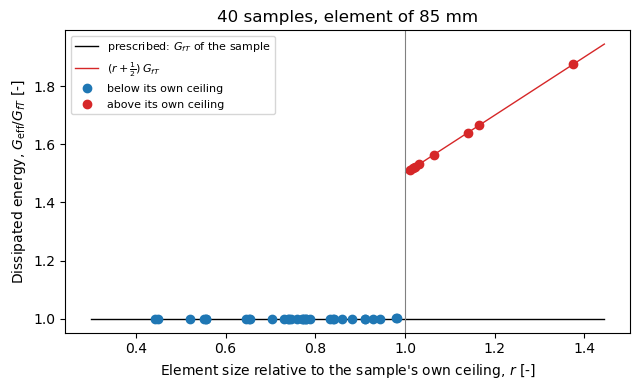

In [7]:
N_RUN = 40                                        # samples run through Abaqus: the first 40 of the streams above


def run_sample(i, lc, e1, x_t, g_ft):
    """Run (or load) sample i: the element of edge lc [mm] with this sample's properties; return its results.

    e1, x_t [MPa] and g_ft [N/mm] are the sampled properties. The run ends at 1.5 (delta_0 + delta_f)
    of this sample, so the element has failed whichever softening branch Abaqus follows.
    """
    u1_end = 1.5 * (lc * x_t / e1 + 2 * g_ft / x_t)                   # 1.5 (delta_0 + delta_f) of this sample [mm]
    data, _ = run_one_sample(x_t, RUNS / "campaign" / f"s{i:03d}.json", u1_end, nlgeom="OFF",
                             G_fT=f"{g_ft:.6f}", E1=f"{e1:.6f}", size=lc, maxinc=MAXINC)    # this sample's properties
    return data                                                       # saved results of the run


r_s, g_eff_s, peak_s = [], [], []                 # per sample: r of its own ceiling, G_eff / G_fT, P_max / (X_T L_c t)
for i in range(N_RUN):
    res = run_sample(i, LC_ELEMENT, e1_s[i], x_t_s[i], g_ft_s[i])     # run or load sample i
    u, p = np.array(res["u1"]), np.array(res["rf1"])                  # displacement [mm] and force [N] of the run
    r_s.append(LC_ELEMENT / lc_max_s[i])                                              # size relative to this sample's ceiling
    g_eff_s.append(dissipated_energy(u, p, LC_ELEMENT, T) / g_ft_s[i])                # energy dissipated, relative to this sample's G_fT
    peak_s.append(p.max() / (x_t_s[i] * LC_ELEMENT * T))                              # peak force relative to strength x area
r_s, g_eff_s, peak_s = np.array(r_s), np.array(g_eff_s), np.array(peak_s)             # lists to arrays
breach = r_s > 1                                  # samples whose own ceiling is below the element

print(f"{breach.sum()} of {N_RUN} samples breach their own ceiling ({breach.mean():.0%}; the formula says {p_breach:.0%})")    # share of breaching samples
print(f"G_eff/G_fT, below the ceiling: {g_eff_s[~breach].min():.2f} to {g_eff_s[~breach].max():.2f}")                  # energy ratio of the safe samples
print(f"G_eff/G_fT, above the ceiling: {g_eff_s[breach].min():.2f} to {g_eff_s[breach].max():.2f} (mean {g_eff_s[breach].mean():.2f})")    # ... and of the breaching ones
print(f"peak force / (X_T L_c t): {peak_s.min():.3f} to {peak_s.max():.3f}")                                           # the strength is untouched

fig, ax = plt.subplots(figsize=(6.5, 4))                                                 # one panel
r_line = np.linspace(0.3, r_s.max() * 1.05, 200)                                        # r values for the reference lines
ax.plot(r_line, np.ones_like(r_line), "k-", lw=1, label=r"prescribed: $G_{fT}$ of the sample")                      # what the study samples
ax.plot(r_line[r_line > 1], r_line[r_line > 1] + 0.5, color="C3", lw=1, label=r"$(r+\frac{1}{2})\,G_{fT}$")        # the rule of Part 3
ax.plot(r_s[~breach], g_eff_s[~breach], "o", color="C0", label="below its own ceiling")                             # samples that respect their ceiling
ax.plot(r_s[breach], g_eff_s[breach], "o", color="C3", label="above its own ceiling")                               # samples that breach it
ax.axvline(1, color="gray", lw=0.8)                                                      # r = 1: the ceiling
ax.set(xlabel=r"Element size relative to the sample's own ceiling, $r$ [-]",
       ylabel=r"Dissipated energy, $G_{\mathrm{eff}}/G_{fT}$ [-]", title=f"{N_RUN} samples, element of {LC_ELEMENT:.0f} mm")
ax.legend(fontsize=8)
fig.tight_layout()                                                                       # avoid overlapping labels
plt.show()

Eight of the 40 samples (20%) breach their own ceiling, close to the 17.7% of the 100,000 samples above. The 32 samples below their ceiling dissipate exactly their own $G_{fT}$. The eight above it sit on the line $(r+\tfrac12)\,G_{fT}$ and dissipate 1.51 to 1.88 times the fracture energy *of their sample*, 1.60 on average. These are the samples with a low $G_{fT}$ or $E_1$, or a high $X_T$.

The peak force is within 1.3% of $X_T\,L_c\,t$ in every run (the recorded peak can fall short by at most one increment). The runs themselves are therefore sound, and the strength of this single element is untouched: only what happens after the onset is affected.

This is a **bias** of the solver. In every run above its ceiling, Abaqus uses a higher fracture energy than the one the study sampled, and the study cannot tell, since no warning mentions it. It is not random scatter that averages out. It appears only where the ceiling is low, that is in one part of the input space, and always in the same direction: more energy.

**One element and a structure are not alike here.** Our element reaches its peak force at the onset, before anything softens, and nothing else carries load. The extra energy is dissipated entirely after the peak, so the peak force stays at $X_T\,L_c\,t$, as the check above shows. In a structure, such as the open-hole plate, the order is different: the peak load comes *after* some elements have softened ([NB6](06_open_hole_tension.ipynb), Part 3), while other material takes up the load they shed. An element that dissipates more than prescribed sheds its load more slowly, so it holds more of the load for longer, and the structure reaches a higher peak. Every output that depends on the softening, the ultimate load first of all, is then shifted upwards in the samples above their ceiling. A surrogate fitted to those outputs would learn the shift as if it were a property of the material.

## Summary

- **Above the ceiling, Abaqus fails the element neither at the onset nor by snap-back, and it says nothing.** It softens along a branch of fixed length $G_{fT}/X_T$ past its onset and dissipates $(r+\tfrac12)\,G_{fT}$, with $r=L_c/L_{c,\max}$. The energy jumps from $G_{fT}$ to $1.5\,G_{fT}$ across the ceiling, then grows with the element size.
- **Below the ceiling the crack band does its job:** the failure displacement is the same for every size, and the energy is exactly $G_{fT}$.
- **With uncertain properties the ceiling is a random variable**, with a CoV of 26% when $E_1$, $G_{fT}$ and $X_T$ each have 10%. An element 20% below the nominal ceiling is above it in 18% of the samples; in the campaign, eight of 40 runs dissipated 1.51 to 1.88 times their own fracture energy.
- **The result is a systematic bias, not scatter.** It affects only the samples with a low ceiling, always in the same direction. Keeping 95% of the samples below the ceiling takes an element a third smaller than the nominal ceiling.
- **The peak of one element is untouched, the peak of a structure is not.** A single element peaks at its onset, before the extra energy is dissipated: all 40 campaign runs peak within 1.3% of $X_T\,L_c\,t$. In a structure the peak comes after elements have softened, so the extra energy raises it.

**What this means for the open-hole plate.** NB6's reference mesh M4 respects the *nominal* matrix-tension ceiling of 1.33 mm. But $E_2$, $G_{mT}$ and $Y_T$ will be uncertain, so that ceiling moves from sample to sample, and some samples will have damaged elements above it. The coarse mesh M1, on which NB9 runs its campaign, breaks the ceiling at the nominal values too, in the outer part of the plate. The runs above the ceiling carry the bias of this notebook, and NB9's campaign will record the share of elements above each sample's own ceiling. Unlike the single element here, the plate's ultimate load will not protected from this bias.

**Where this goes next.** [NB8](08_polynomial_chaos_expansion.ipynb) introduces polynomial chaos expansion on a test function with known coefficients, [NB9](09_training_campaign_open_hole_tension.ipynb) plans and runs the Abaqus campaign that trains a surrogate of the open-hole plate, and NB10 fits it.